# Exploring Give Me Some Credit: Who Becomes Delinquent?

**Author:** Payaz Mohammed, PhD student in Artificial Intelligence, University of the Cumberlands

This notebook explores the **Give Me Some Credit** dataset (150,000 borrowers) before any modeling. The goal is to understand the data the way a credit risk analyst would:

1. How common is serious delinquency?
2. Where is data missing or unusual?
3. Which borrower characteristics are linked to delinquency?

The target, `SeriousDlqin2yrs`, is 1 if a borrower was 90 or more days past due within two years.

This is part of a series on explainable, fair AI for credit unions. Code is also on [GitHub](https://github.com/MOHAMMEDPAYAZ/credit-risk-stats-series).

**Data source:** Credit Fusion & Kaggle. (2011). *Give Me Some Credit* [Data set]. https://www.kaggle.com/competitions/GiveMeSomeCredit

## 1. Setup and load the data

In [2]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

# Finds the file on Kaggle (/kaggle/input/...) or in a local ../data folder
paths = glob.glob("/kaggle/input/**/cs-training.csv", recursive=True) + glob.glob("../data/cs-training.csv")
df = pd.read_csv(paths[0], index_col=0)

print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
df.head()

Matplotlib is building the font cache; this may take a moment.


Rows: 150,000  Columns: 11


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766,45,2,0.803,"9,120.000",13,0,6,0,2.000
2,0,0.957,40,0,0.122,"2,600.000",4,0,0,0,1.000
3,0,0.658,38,1,0.085,"3,042.000",2,1,0,0,0.000
4,0,0.234,30,0,0.036,"3,300.000",5,0,0,0,0.000
5,0,0.907,49,1,0.025,"63,588.000",7,0,1,0,0.000


## 2. What each column means

| Column | Meaning |
|---|---|
| SeriousDlqin2yrs | **Target.** 90+ days past due within 2 years (1 = yes) |
| RevolvingUtilizationOfUnsecuredLines | Credit card and personal line balances divided by their limits |
| age | Borrower age in years |
| NumberOfTime30-59DaysPastDueNotWorse | Times 30–59 days late in the last 2 years |
| DebtRatio | Monthly debt payments divided by monthly income |
| MonthlyIncome | Monthly income |
| NumberOfOpenCreditLinesAndLoans | Open loans and credit lines |
| NumberOfTimes90DaysLate | Times 90+ days late |
| NumberRealEstateLoansOrLines | Mortgage and real estate loans |
| NumberOfTime60-89DaysPastDueNotWorse | Times 60–89 days late in the last 2 years |
| NumberOfDependents | Dependents, excluding the borrower |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

## 3. How common is serious delinquency?

In credit data, the event we care about is usually rare. That matters: a model that predicts "no delinquency" for everyone can look highly accurate while being useless.

Delinquency rate: 6.7%
A model that always predicts 'no' would be 93.3% accurate, and catch zero delinquent borrowers.


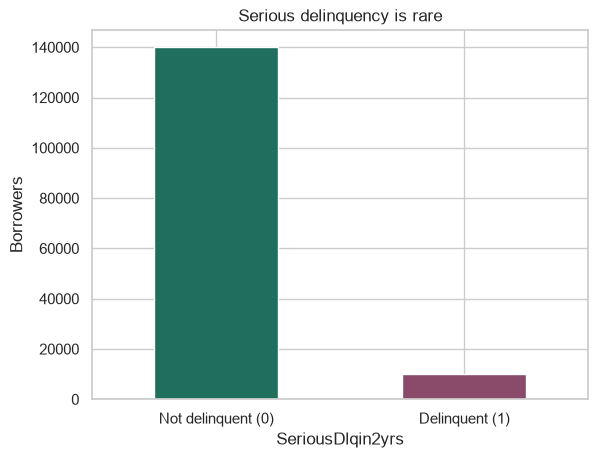

In [4]:
rate = df["SeriousDlqin2yrs"].mean()
print(f"Delinquency rate: {rate:.1%}")
print(f"A model that always predicts 'no' would be {1 - rate:.1%} accurate, and catch zero delinquent borrowers.")

ax = df["SeriousDlqin2yrs"].value_counts().sort_index().plot(kind="bar", color=["#1F6F5C", "#8A4B6B"])
ax.set_xticklabels(["Not delinquent (0)", "Delinquent (1)"], rotation=0)
ax.set_ylabel("Borrowers")
ax.set_title("Serious delinquency is rare")
plt.show()

## 4. Missing values

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = missing["missing"] / len(df) * 100
missing

,missing,percent
MonthlyIncome,29731,19.821
NumberOfDependents,3924,2.616


In [6]:
# Is delinquency different when income is missing?
df.groupby(df["MonthlyIncome"].isnull())["SeriousDlqin2yrs"].mean().rename(
    {False: "Income reported", True: "Income missing"}).to_frame("delinquency rate")

,delinquency rate
MonthlyIncome,
Income reported,0.069
Income missing,0.056


Missing data is not always random. If borrowers with missing income behave differently, simply dropping those rows could bias a model.

## 5. Summary statistics and unusual values

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,"150,000.000",0.067,0.250,0.000,0.000,0.000,0.000,1.000
RevolvingUtilizationOfUnsecuredLines,"150,000.000",6.048,249.755,0.000,0.030,0.154,0.559,"50,708.000"
age,"150,000.000",52.295,14.772,0.000,41.000,52.000,63.000,109.000
NumberOfTime30-59DaysPastDueNotWorse,"150,000.000",0.421,4.193,0.000,0.000,0.000,0.000,98.000
DebtRatio,"150,000.000",353.005,"2,037.819",0.000,0.175,0.367,0.868,"329,664.000"
MonthlyIncome,"120,269.000","6,670.221","14,384.674",0.000,"3,400.000","5,400.000","8,249.000","3,008,750.000"
NumberOfOpenCreditLinesAndLoans,"150,000.000",8.453,5.146,0.000,5.000,8.000,11.000,58.000
NumberOfTimes90DaysLate,"150,000.000",0.266,4.169,0.000,0.000,0.000,0.000,98.000
NumberRealEstateLoansOrLines,"150,000.000",1.018,1.130,0.000,0.000,1.000,2.000,54.000
NumberOfTime60-89DaysPastDueNotWorse,"150,000.000",0.240,4.155,0.000,0.000,0.000,0.000,98.000


In [8]:
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
             "NumberOfTime60-89DaysPastDueNotWorse",
             "NumberOfTimes90DaysLate"]

print("Borrowers with age 0:", (df["age"] == 0).sum())
print("Utilization above 100% of limits:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
for c in late_cols:
    print(f"{c}: values of 96 or 98 -> {(df[c] >= 96).sum()}")

Borrowers with age 0: 1
Utilization above 100% of limits: 3321
NumberOfTime30-59DaysPastDueNotWorse: values of 96 or 98 -> 269
NumberOfTime60-89DaysPastDueNotWorse: values of 96 or 98 -> 269
NumberOfTimes90DaysLate: values of 96 or 98 -> 269


Values like 96 and 98 late payments in two years are not realistic and are likely codes for missing or special cases. An age of 0 is a data error. These need cleaning before modeling. Checking for them first is part of building a model you can trust.

## 6. Delinquency by age group

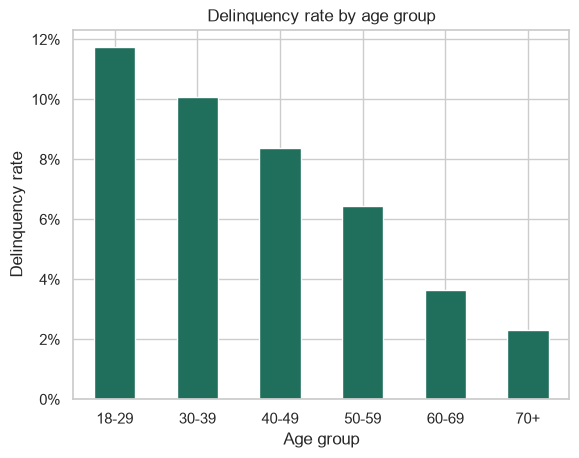

,delinquency rate
age,
18-29,0.117
30-39,0.101
40-49,0.084
50-59,0.065
60-69,0.036
70+,0.023


In [9]:
age_groups = pd.cut(df["age"], bins=[18, 30, 40, 50, 60, 70, 110],
                    labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70+"], right=False)
by_age = df.groupby(age_groups, observed=True)["SeriousDlqin2yrs"].mean()

ax = by_age.plot(kind="bar", color="#1F6F5C")
ax.set_ylabel("Delinquency rate")
ax.set_xlabel("Age group")
ax.set_title("Delinquency rate by age group")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.xticks(rotation=0)
plt.show()
by_age.to_frame("delinquency rate")

Age can be a legally protected characteristic in lending decisions. A pattern here is worth understanding, but it raises fairness questions about how such a variable should be used in a real credit model.

## 7. Past late payments and future delinquency

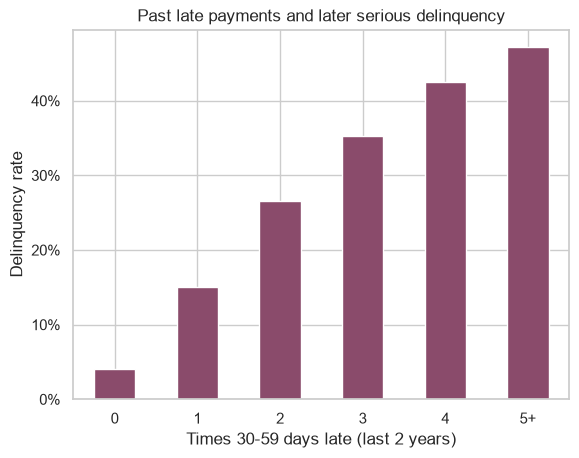

In [10]:
late = df["NumberOfTime30-59DaysPastDueNotWorse"].clip(upper=5)
late = late[df["NumberOfTime30-59DaysPastDueNotWorse"] < 96]
by_late = df.loc[late.index].groupby(late)["SeriousDlqin2yrs"].mean()

ax = by_late.plot(kind="bar", color="#8A4B6B")
ax.set_xticklabels([f"{int(i)}+" if i == 5 else str(int(i)) for i in by_late.index], rotation=0)
ax.set_xlabel("Times 30-59 days late (last 2 years)")
ax.set_ylabel("Delinquency rate")
ax.set_title("Past late payments and later serious delinquency")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

## 8. Revolving credit utilization

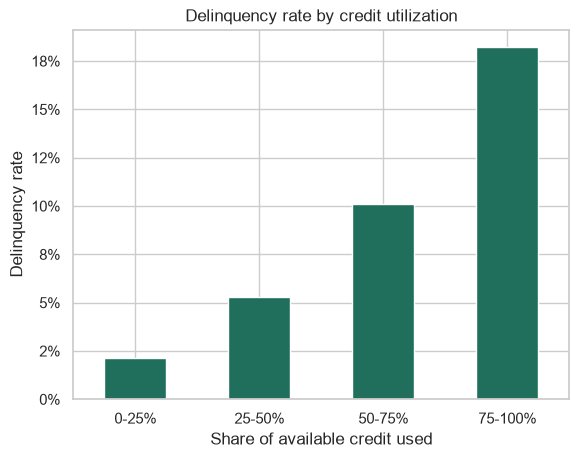

In [11]:
util = df["RevolvingUtilizationOfUnsecuredLines"]
util_groups = pd.cut(util[util <= 1], bins=[0, 0.25, 0.5, 0.75, 1.0], include_lowest=True,
                     labels=["0-25%", "25-50%", "50-75%", "75-100%"])
by_util = df.loc[util_groups.index].groupby(util_groups, observed=True)["SeriousDlqin2yrs"].mean()

ax = by_util.plot(kind="bar", color="#1F6F5C")
ax.set_xlabel("Share of available credit used")
ax.set_ylabel("Delinquency rate")
ax.set_title("Delinquency rate by credit utilization")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.xticks(rotation=0)
plt.show()

## 9. Correlations with the target

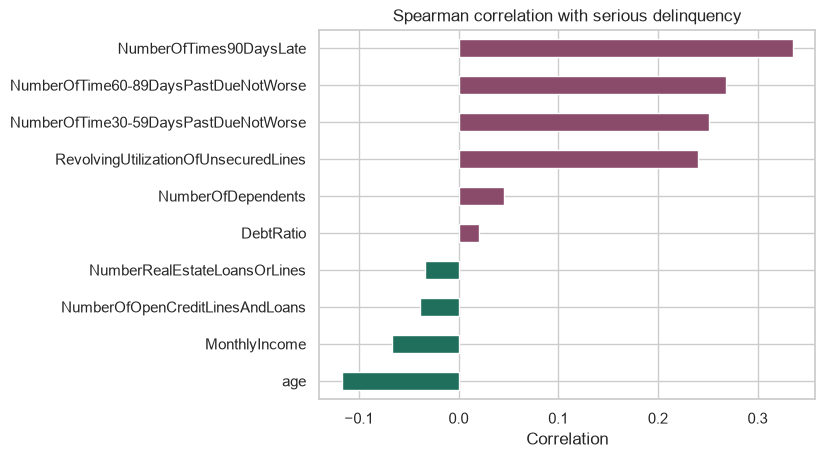

,correlation
age,-0.117
MonthlyIncome,-0.067
NumberOfOpenCreditLinesAndLoans,-0.039
NumberRealEstateLoansOrLines,-0.034
DebtRatio,0.021
NumberOfDependents,0.046
RevolvingUtilizationOfUnsecuredLines,0.240
NumberOfTime30-59DaysPastDueNotWorse,0.251
NumberOfTime60-89DaysPastDueNotWorse,0.268
NumberOfTimes90DaysLate,0.335


In [12]:
clean = df.copy()
for c in late_cols:
    clean.loc[clean[c] >= 96, c] = np.nan

corr = clean.corr(method="spearman")["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs").sort_values()
ax = corr.plot(kind="barh", color=["#8A4B6B" if v > 0 else "#1F6F5C" for v in corr])
ax.set_title("Spearman correlation with serious delinquency")
ax.set_xlabel("Correlation")
plt.show()
corr.to_frame("correlation")

I used **Spearman** correlation because many of these columns are skewed and have extreme values; it measures whether values rise and fall together in rank order. Correlation is not causation: these are associations to investigate, not reasons a borrower became delinquent.

### 10. Key takeaways

- **Delinquency is rare:** only 6.7% of borrowers became seriously delinquent. A model that always predicts "no" would be 93.3% accurate but catch no delinquent borrowers, so metrics like recall and precision matter more than accuracy.
- **Missing data is not random:** 19.8% of borrowers (29,731) have no reported income, and 2.6% (3,924) have no dependents count. Borrowers with missing income had a *lower* delinquency rate (5.6%) than those who reported it (6.9%), so dropping or blindly filling these rows could bias a model.
- **Past late payments are the strongest signal:** delinquency rose from about 4% for borrowers never 30–59 days late to nearly 47% for those late five or more times. All three late-payment measures had the highest correlations with delinquency (0.25 to 0.34).
- **Credit utilization matters too** (correlation 0.24), while debt ratio showed almost no relationship (0.02), a reminder to test assumptions against the data.
- **Age shows a negative relationship** (−0.12): older borrowers were less likely to become delinquent. Because age is a protected characteristic in lending, this needs careful fairness review before use in a real model.
- **No single variable explains delinquency on its own.** The strongest correlation is only 0.34, so combining variables in a model should help.

**Next in this series:** cleaning the data and building an explainable delinquency model.

If you found this useful, an upvote helps others find it. Feedback is welcome in the comments.